# Figures for *Predator--Prey Dynamics from Growth Cycles to Financial Instability: Deterministic Structure and Stochastic Fragility*

This notebook regenerates the five figures of the manuscript.

| Cell | Figure | Output file | Manuscript object |
|------|--------|-------------|-------------------|
| Fig 1 | Classical Lotka--Volterra | `fig1_basic_lotka_volterra.png` | Fig. 1 / Prop. 2.2 |
| Fig 2 | Goodwin growth cycle | `fig2_goodwin_model.png` | Fig. 2 / Prop. 3.2 |
| Fig 3 | Debt--capital + noise drift | `fig3_debt_capital_new.png` | Fig. 3 / Thm. 4.4 |
| Fig 4 | Three-species super-predator | `fig4_super_predator.png` | Fig. 4 / Thm. 4.7 |
| Fig 5 | Stochastic agent-based market | `fig5_abm_market.png` | Fig. 5 / Thm. 5.1 |

## Setup: imports and shared plotting style

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.stats import kurtosis

plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "cm",
    "font.size": 11, "axes.labelsize": 12, "axes.titlesize": 12.5,
    "legend.fontsize": 9, "figure.dpi": 150, "savefig.dpi": 300,
    "lines.linewidth": 1.6, "axes.grid": True, "grid.alpha": 0.30,
})
C_PREY, C_PRED, C_THIRD = "#2166ac", "#d6604d", "#1a9850"

## Figure 1: Classical Lotka-Volterra predator-prey

fig1 done: E*=(10,10) T=8.89


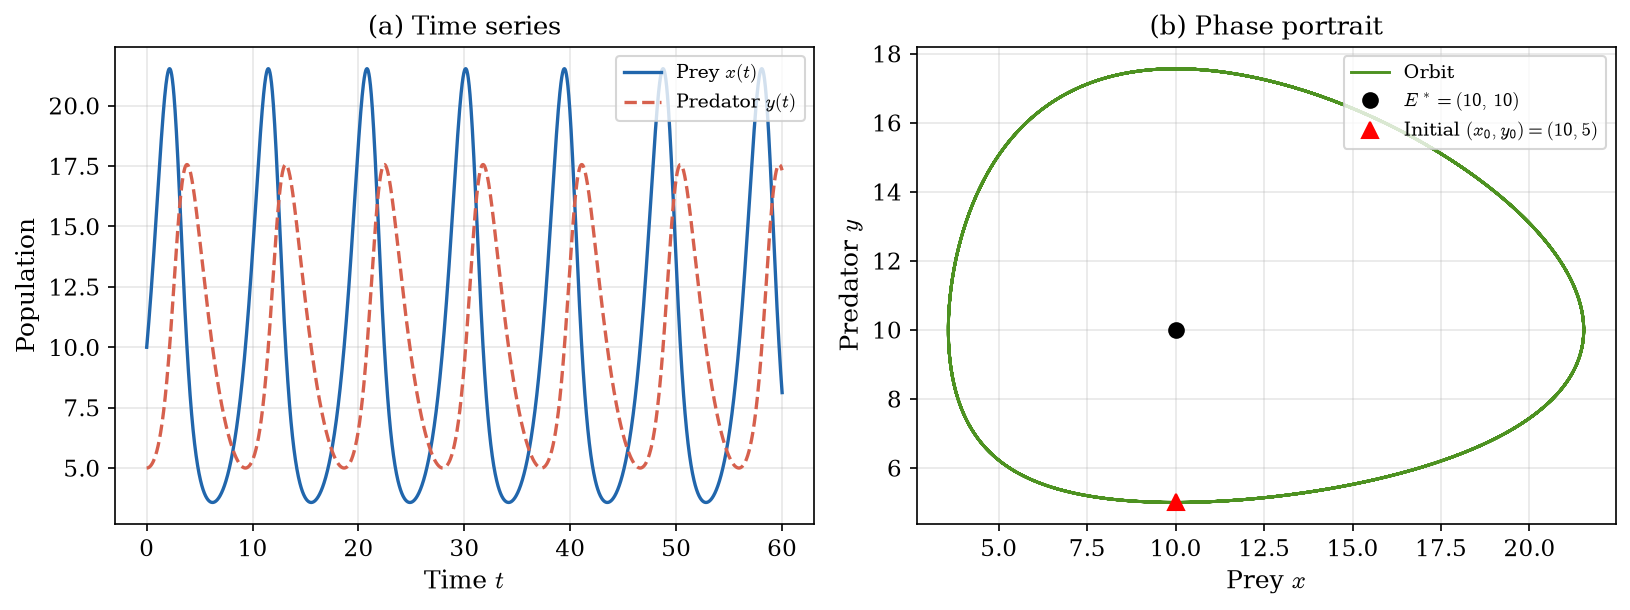

In [5]:
# ---- Figure 1: classical Lotka-Volterra ----
def lotka_volterra(t, s, r, a, m, b):
    x, y = s
    return [r*x - a*x*y, -m*y + b*x*y]

r, a, m, b = 1.0, 0.10, 0.5, 0.05
x0, y0 = 10.0, 5.0
x_eq, y_eq = m/b, r/a                      # E* = (10, 10)
T = 2*np.pi/np.sqrt(r*m)                    # ~ 8.89
sol = solve_ivp(lotka_volterra, (0, 60), [x0, y0], args=(r, a, m, b),
                max_step=0.02, dense_output=True)
t = np.linspace(0, 60, 3000); x_t, y_t = sol.sol(t)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(t, x_t, color=C_PREY, label=r"Prey $x(t)$")
ax[0].plot(t, y_t, color=C_PRED, ls="--", label=r"Predator $y(t)$")
ax[0].set_xlabel(r"Time $t$"); ax[0].set_ylabel("Population")
ax[0].set_title("(a) Time series"); ax[0].legend(loc="upper right")
ax[1].plot(x_t, y_t, color="#4d9221", lw=1.4, label="Orbit")
ax[1].plot(x_eq, y_eq, "ko", ms=7, label=r"$E^*=(10,\,10)$")
ax[1].plot(x0, y0, "r^", ms=8, label=r"Initial $(x_0,y_0)=(10,5)$")
ax[1].set_xlabel(r"Prey $x$"); ax[1].set_ylabel(r"Predator $y$")
ax[1].set_title("(b) Phase portrait"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.savefig("fig1_basic_lotka_volterra.png", bbox_inches="tight")
print("fig1 done: E*=(%.0f,%.0f) T=%.2f" % (x_eq, y_eq, T))

## Figure 2: Goodwin growth-cycle model

fig2 done: E*=(0.900,0.8125) T=55.1


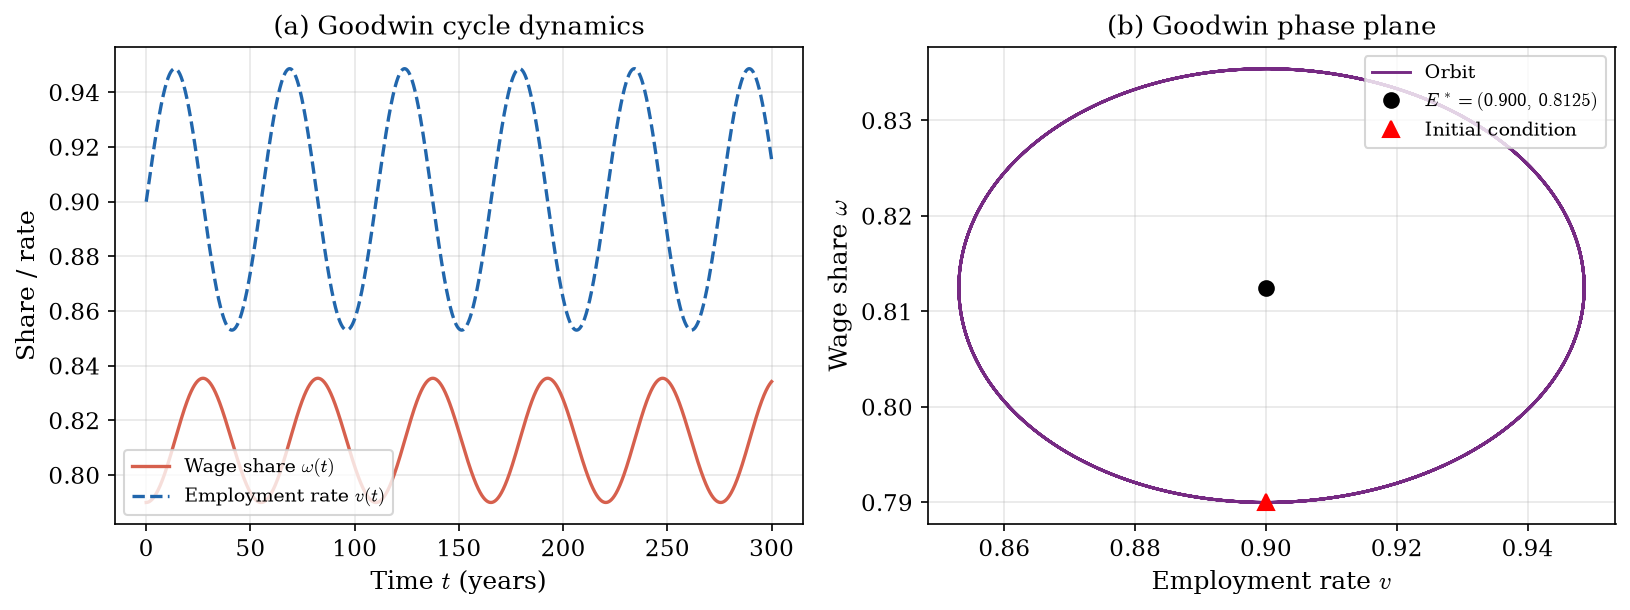

In [6]:
# ---- Figure 2: Goodwin growth cycle (recalibrated, unified alpha) ----
alpha, beta, gamma, rho, nu, s = 0.03, 0.02, 0.03, 1/15, 3.0, 0.8
v_star  = (gamma + alpha)/rho              # 0.900
om_star = 1 - (alpha + beta)*nu/s          # 0.8125
r_lv, m_lv = s/nu - (alpha+beta), gamma+alpha
T = 2*np.pi/np.sqrt(r_lv*m_lv)             # ~ 55 yr

def goodwin(t, y):
    om, v = y
    return [om*(-(gamma+alpha) + rho*v),
            v*(s*(1-om)/nu - (alpha+beta))]

sol = solve_ivp(goodwin, (0, 300), [0.79, 0.90],
                t_eval=np.linspace(0, 300, 5000), rtol=1e-10, atol=1e-12)
om_t, v_t = sol.y

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(sol.t, om_t, color=C_PRED, label=r"Wage share $\omega(t)$")
ax[0].plot(sol.t, v_t, color=C_PREY, ls="--", label=r"Employment rate $v(t)$")
ax[0].set_xlabel(r"Time $t$ (years)"); ax[0].set_ylabel("Share / rate")
ax[0].set_title("(a) Goodwin cycle dynamics"); ax[0].legend(loc="lower left")
ax[1].plot(v_t, om_t, color="#762a83", lw=1.4, label="Orbit")
ax[1].plot(v_star, om_star, "ko", ms=7,
           label=r"$E^*=(%.3f,\,%.4f)$" % (v_star, om_star))
ax[1].plot(0.90, 0.79, "r^", ms=8, label="Initial condition")
ax[1].set_xlabel(r"Employment rate $v$"); ax[1].set_ylabel(r"Wage share $\omega$")
ax[1].set_title("(b) Goodwin phase plane"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.savefig("fig2_goodwin_model.png", bbox_inches="tight")
print("fig2 done: E*=(%.3f,%.4f) T=%.1f" % (v_star, om_star, T))

## Figure 3: Debt--capital predator-prey and noise-induced drift

fig3 done: drift slope theory=1.250e-04 MC=1.311e-04


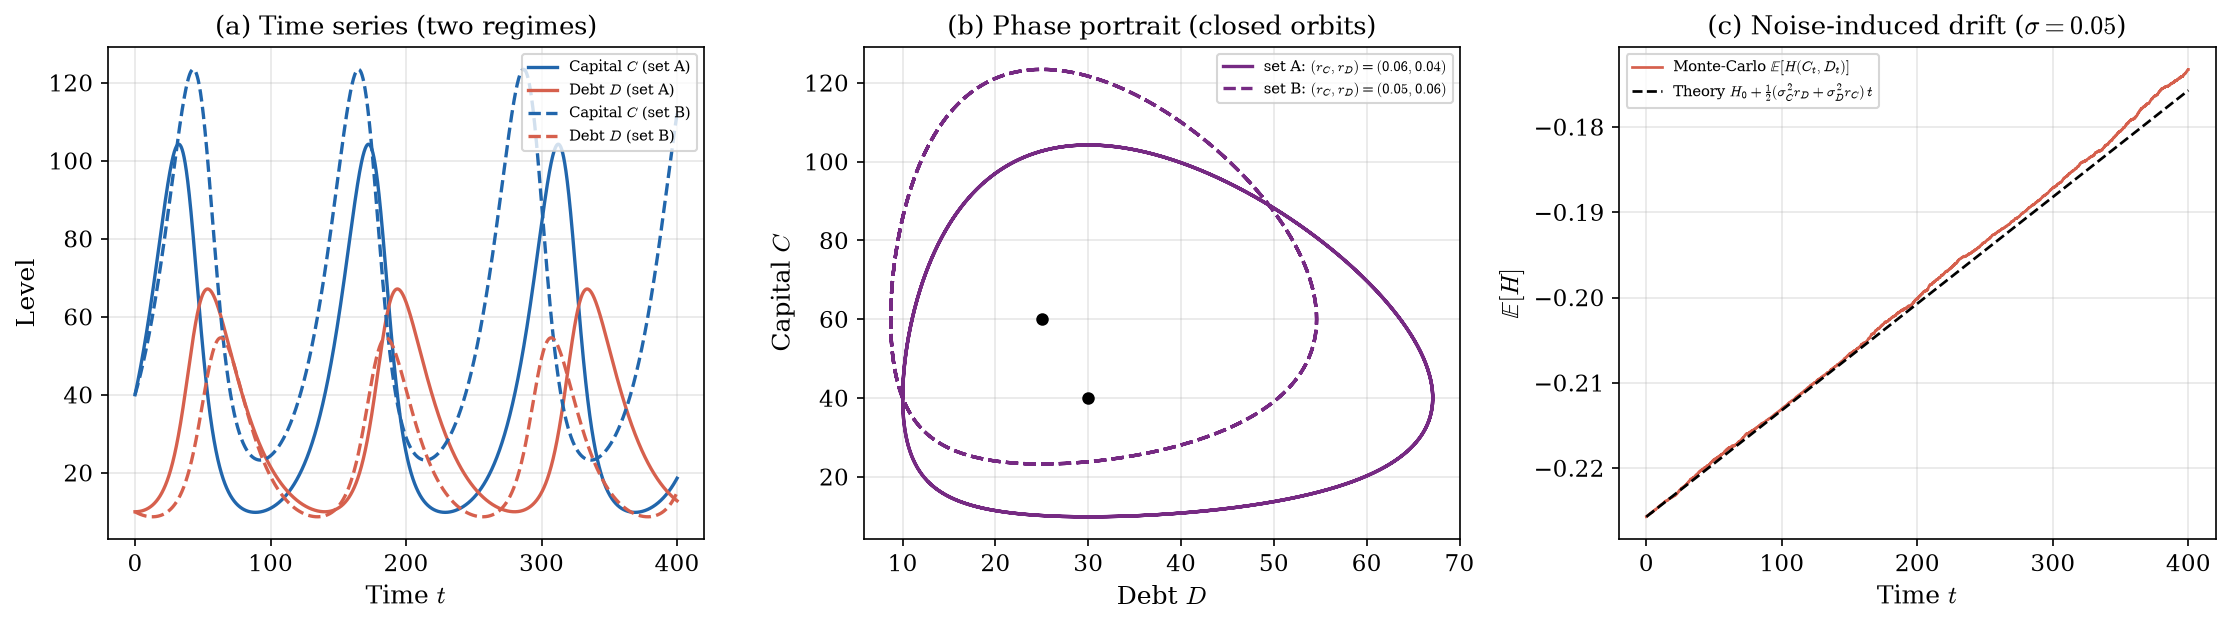

In [8]:
# ---- Figure 3: debt-capital predator-prey (corrected) + noise drift ----
a_DC, b_DC = 0.002, 0.001
def debtcap(t, s, rC, rD):
    C, D = s
    return [rC*C - a_DC*C*D, -rD*D + b_DC*C*D]

# two parameter regimes; BOTH are neutral centres (closed orbits)
regimes = [(0.06, 0.04, "A"), (0.05, 0.06, "B")]
C0, D0 = 40.0, 10.0

fig = plt.figure(figsize=(15, 4.3))
axA = fig.add_subplot(1, 3, 1); axB = fig.add_subplot(1, 3, 2)
axC = fig.add_subplot(1, 3, 3)
styles = ["-", "--"]
for (rC, rD, lab), ls in zip(regimes, styles):
    sol = solve_ivp(debtcap, (0, 400), [C0, D0], args=(rC, rD),
                    t_eval=np.linspace(0, 400, 4000), rtol=1e-10, atol=1e-12)
    C_t, D_t = sol.y
    axA.plot(sol.t, C_t, color=C_PREY, ls=ls,
             label=r"Capital $C$ (set %s)" % lab)
    axA.plot(sol.t, D_t, color=C_PRED, ls=ls,
             label=r"Debt $D$ (set %s)" % lab)
    axB.plot(D_t, C_t, ls=ls, color="#762a83",
             label=r"set %s: $(r_C,r_D)=(%.2f,%.2f)$" % (lab, rC, rD))
    axB.plot(rC/a_DC, rD/b_DC, "ko", ms=5)   # E* = (D*, C*) on the (D, C) axes
axA.set_xlabel(r"Time $t$"); axA.set_ylabel("Level")
axA.set_title("(a) Time series (two regimes)"); axA.legend(fontsize=7, loc="upper right")
axB.set_xlabel(r"Debt $D$"); axB.set_ylabel(r"Capital $C$")
axB.set_title("(b) Phase portrait (closed orbits)"); axB.legend(fontsize=7, loc="upper right")

# panel (c): Monte-Carlo E[H] under multiplicative Ito noise vs theory
rC, rD, sig = 0.06, 0.04, 0.05
rng = np.random.default_rng(0)
Tmax, dt, npath = 400.0, 0.05, 4000
nstep = int(Tmax/dt); ts = np.arange(nstep+1)*dt
Cw = np.full(npath, C0); Dw = np.full(npath, D0)
Hf = lambda C, D: b_DC*C - rD*np.log(C) + a_DC*D - rC*np.log(D)
EH = np.empty(nstep+1); EH[0] = Hf(Cw, Dw).mean()
sq = np.sqrt(dt)
for k in range(nstep):
    Cn = Cw + (rC*Cw - a_DC*Cw*Dw)*dt + sig*Cw*rng.standard_normal(npath)*sq
    Dn = Dw + (-rD*Dw + b_DC*Cw*Dw)*dt + sig*Dw*rng.standard_normal(npath)*sq
    Cw = np.maximum(Cn, 1e-6); Dw = np.maximum(Dn, 1e-6)
    EH[k+1] = Hf(Cw, Dw).mean()
theory = EH[0] + 0.5*(sig**2*rD + sig**2*rC)*ts
axC.plot(ts, EH, color=C_PRED, lw=1.3, label=r"Monte-Carlo $\mathbb{E}[H(C_t,D_t)]$")
axC.plot(ts, theory, "k--", lw=1.3,
         label=r"Theory $H_0+\frac{1}{2}(\sigma_C^2 r_D+\sigma_D^2 r_C)\,t$")
axC.set_xlabel(r"Time $t$"); axC.set_ylabel(r"$\mathbb{E}[H]$")
axC.set_title(r"(c) Noise-induced drift ($\sigma=0.05$)"); axC.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig("fig3_debt_capital.png", bbox_inches="tight")
print("fig3 done: drift slope theory=%.3e MC=%.3e" % (0.5*sig**2*(rC+rD), (EH[-1]-EH[0])/Tmax))

## Figure 4: Three-species financial super-predator

<>:27: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:27: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_5326/1702355555.py:27: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax2.set_title("(b) Phase portrait in $(C,D,\mathcal{S})$")


fig4 done: ranges C[0.1,140.2] D[0.0,10.0] S[2.00,108.98]


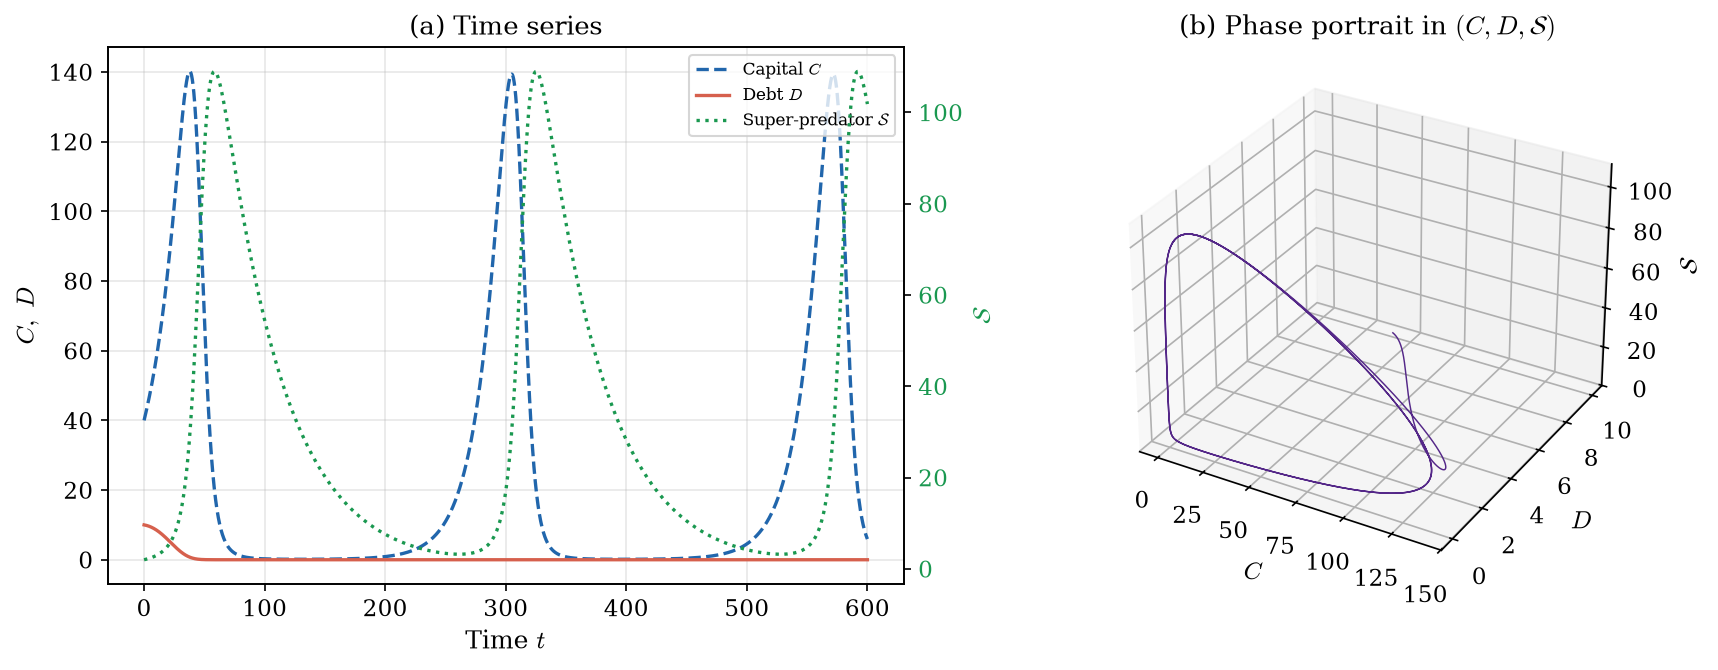

In [9]:
# ---- Figure 4: three-species financial super-predator (eq. 3s) ----
rC, rD, rS = 0.06, 0.04, 0.02
a_DC, b_DC, c_DS, e_CS, f_DC, g_CS = 0.002, 0.001, 0.003, 0.002, 5e-5, 0.001
def superpred(t, s):
    C, D, S = s
    return [rC*C - a_DC*D*C - e_CS*C*S,
            rD*D - b_DC*D*C - c_DS*D*S,
            -rS*S + f_DC*D*C + g_CS*C*S]
sol = solve_ivp(superpred, (0, 600), [40.0, 10.0, 2.0],
                t_eval=np.linspace(0, 600, 8000), rtol=1e-10, atol=1e-12)
C_t, D_t, S_t = sol.y

fig = plt.figure(figsize=(12, 4.6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(sol.t, C_t, color=C_PREY, ls="--", label=r"Capital $C$")
ax1.plot(sol.t, D_t, color=C_PRED, label=r"Debt $D$")
ax1.set_xlabel(r"Time $t$"); ax1.set_ylabel(r"$C,\;D$")
axr = ax1.twinx(); axr.grid(False)
axr.plot(sol.t, S_t, color=C_THIRD, ls=":", label=r"Super-predator $\mathcal{S}$")
axr.set_ylabel(r"$\mathcal{S}$", color=C_THIRD); axr.tick_params(axis="y", labelcolor=C_THIRD)
l1, lb1 = ax1.get_legend_handles_labels(); l2, lb2 = axr.get_legend_handles_labels()
ax1.legend(l1+l2, lb1+lb2, fontsize=8, loc="upper right")
ax1.set_title("(a) Time series")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(C_t, D_t, S_t, color="#542788", lw=0.7)
ax2.set_xlabel(r"$C$"); ax2.set_ylabel(r"$D$"); ax2.set_zlabel(r"$\mathcal{S}$")
ax2.set_title("(b) Phase portrait in $(C,D,\mathcal{S})$")
plt.tight_layout(); plt.savefig("fig4_super_predator.png", bbox_inches="tight")
print("fig4 done: ranges C[%.1f,%.1f] D[%.1f,%.1f] S[%.2f,%.2f]" %
      (C_t.min(),C_t.max(),D_t.min(),D_t.max(),S_t.min(),S_t.max()))

## Figure 5: Stochastic agent-based buyer-seller market

fig5 done: excess kurtosis=1.52


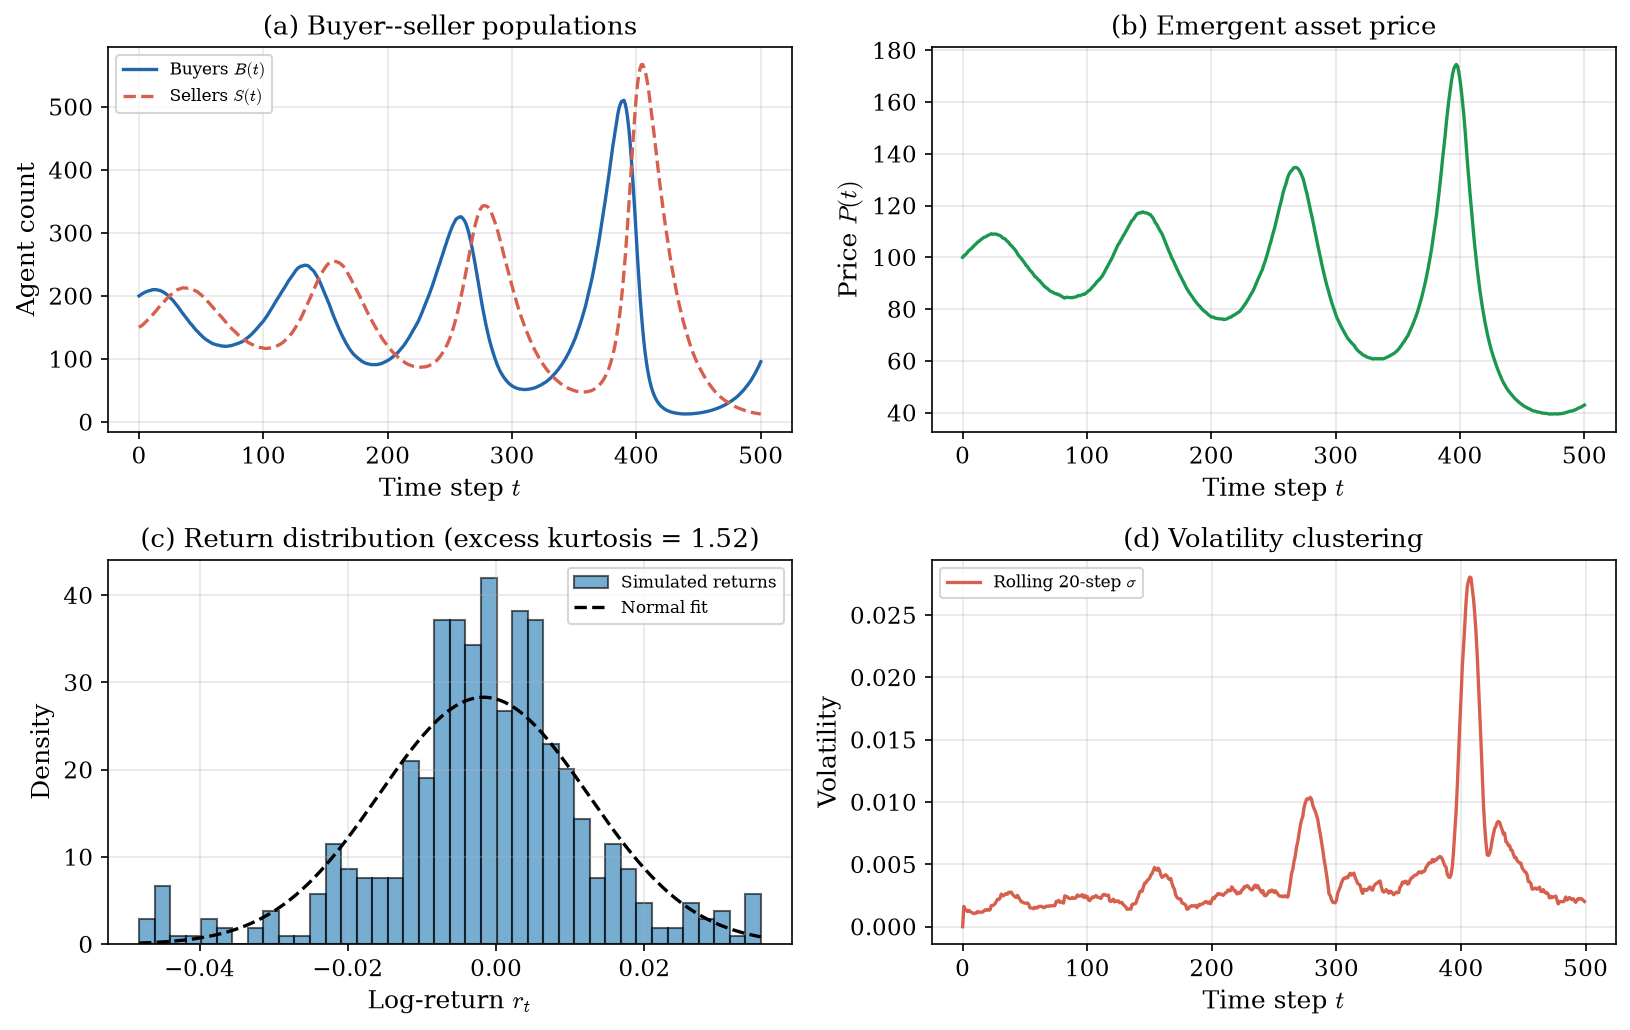

In [11]:
# ---- Figure 5: stochastic agent-based buyer-seller market (corrected signs) ----
rB0, mS, aBS, bBS = 0.05, 0.05, 3e-4, 3e-4
sigma0, sigmaP0, eta, kappa = 0.04, 0.05, 0.1, 0.4
N, Tsteps, dt = 1000, 500, 1.0
sigma, sigmaP = sigma0/np.sqrt(N), sigmaP0/np.sqrt(N)
rng = np.random.default_rng(42)
B = np.zeros(Tsteps+1); S = np.zeros(Tsteps+1); P = np.zeros(Tsteps+1)
B[0], S[0], P[0] = 200.0, 150.0, 100.0
for t in range(Tsteps):
    rB = rB0 + (kappa*(P[t]-P[t-1])/P[t-1] if t >= 1 else 0.0)
    B[t+1] = B[t] + dt*(rB*B[t]-aBS*B[t]*S[t]) + sigma*B[t]*np.sqrt(dt)*rng.standard_normal()
    S[t+1] = S[t] + dt*(-mS*S[t]+bBS*B[t]*S[t]) + sigma*S[t]*np.sqrt(dt)*rng.standard_normal()
    P[t+1] = P[t]*(1 + eta*(B[t]-S[t])/N + sigmaP*np.sqrt(dt)*rng.standard_normal())
    B[t+1] = max(B[t+1], 1e-6); S[t+1] = max(S[t+1], 1e-6); P[t+1] = max(P[t+1], 1e-6)
ret = np.diff(np.log(P))
roll = np.array([ret[max(0,i-20):i+1].std() for i in range(len(ret))])
exk = kurtosis(ret)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0,0].plot(B, color=C_PREY, label=r"Buyers $B(t)$")
ax[0,0].plot(S, color=C_PRED, ls="--", label=r"Sellers $S(t)$")
ax[0,0].set_title("(a) Buyer--seller populations"); ax[0,0].set_xlabel(r"Time step $t$")
ax[0,0].set_ylabel("Agent count"); ax[0,0].legend(fontsize=8)
ax[0,1].plot(P, color=C_THIRD); ax[0,1].set_title("(b) Emergent asset price")
ax[0,1].set_xlabel(r"Time step $t$"); ax[0,1].set_ylabel(r"Price $P(t)$")
ax[1,0].hist(ret, bins=40, density=True, edgecolor="black", alpha=0.6, label="Simulated returns")
xx = np.linspace(ret.min(), ret.max(), 200)
ax[1,0].plot(xx, np.exp(-(xx-ret.mean())**2/(2*ret.std()**2))/(ret.std()*np.sqrt(2*np.pi)),
             "k--", label=r"Normal fit")
ax[1,0].set_title("(c) Return distribution (excess kurtosis = %.2f)" % exk)
ax[1,0].set_xlabel(r"Log-return $r_t$"); ax[1,0].set_ylabel("Density"); ax[1,0].legend(fontsize=8)
ax[1,1].plot(roll, color=C_PRED, label=r"Rolling 20-step $\sigma$")
ax[1,1].set_title("(d) Volatility clustering"); ax[1,1].set_xlabel(r"Time step $t$")
ax[1,1].set_ylabel("Volatility"); ax[1,1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig5_abm_market.png", bbox_inches="tight")
print("fig5 done: excess kurtosis=%.2f" % exk)